<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_2_bloque_transformer.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_2_bloque_transformer.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_2_bloque_transformer.ipynb)

# SI7011 · Sesión 06 · 2. El bloque Transformer, en la tarea de las fechas
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña la **Parte 2** de las diapositivas. Armamos el bloque pre-norm con las piezas de la sesión 02 y la atención del notebook 6.1, contamos sus parámetros, y lo ponemos a resolver la **misma tarea del notebook 5.5**: una frase en español con una fecha en palabras → la fecha en formato ISO.

> "el contrato se firmó el veintinueve de septiembre de mil novecientos noventa y ocho sin falta" → `1998-09-29`

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | el bloque pre-norm | $12d^2$ parámetros |
| 2 | los datos de 5.5, las mismas semillas | nada nuevo |
| 3 | un Transformer codificador-decodificador | máscaras, posición, decodificar |
| 5 | el modelo de 5.5, entrenado **aquí** | la referencia, en la misma máquina |
| 6 | el Transformer | segundos por época, épocas hasta acertar |
| 7 | el Transformer **sin posición** | ¿qué fechas confunde? |
| 8 | 6 capas, pre-norm contra post-norm, sin warmup | ¿cuál entrena? |

**Datos:** se generan en el notebook. Con GPU (Kaggle o Colab) tarda unos minutos; en CPU, unos 20 (la sección 8 es la más lenta: puedes dejarla para después).

In [1]:
import json, math, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '·', dev)

PyTorch 2.14.1+cu130 · cpu


## 1. El bloque
Dos subcapas, cada una con su camino residual (diapositiva 24):

$$X \leftarrow X + \mathrm{MHA}(\mathrm{LN}(X)), \qquad X \leftarrow X + \mathrm{MLP}(\mathrm{LN}(X))$$

Usamos `nn.MultiheadAttention`, que en el notebook 6.1 comprobamos que hace lo mismo que nuestra atención. El interruptor `pre_norm` sirve para la sección 8; `cruzada` agrega la atención cruzada que necesita el decodificador (diapositiva 31).

In [2]:
class Bloque(nn.Module):
    """Bloque pre-norm: X <- X + MHA(LN(X)); X <- X + MLP(LN(X))  (diapositiva 24)."""
    def __init__(self, d, H, cruzada=False, pre_norm=True, p=0.1):
        super().__init__()
        self.pre_norm = pre_norm
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.att = nn.MultiheadAttention(d, H, dropout=p, batch_first=True)          # 4d² (+4d sesgos)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))  # 8d² (+5d sesgos)
        self.drop = nn.Dropout(p)
        self.cruzada = cruzada
        if cruzada:                                                # solo en el decodificador encoder-decoder
            self.ln_c = nn.LayerNorm(d)
            self.att_c = nn.MultiheadAttention(d, H, dropout=p, batch_first=True)

    def _sub(self, X, f, ln):
        if self.pre_norm:
            return X + self.drop(f(ln(X)))                         # pre-norm: el camino residual queda limpio
        return ln(X + self.drop(f(X)))                             # post-norm: LN sobre el camino residual

    def forward(self, X, mascara=None, pad=None, memoria=None, pad_mem=None):
        X = self._sub(X, lambda Z: self.att(Z, Z, Z, attn_mask=mascara, key_padding_mask=pad,
                                            need_weights=False)[0], self.ln1)
        if self.cruzada:                                           # queries del decodificador, keys/values del codificador
            X = self._sub(X, lambda Z: self.att_c(Z, memoria, memoria, key_padding_mask=pad_mem,
                                                  need_weights=False)[0], self.ln_c)
        return self._sub(X, self.mlp, self.ln2)

**Contar parámetros** (diapositiva 30): $4d^2$ en la atención y $8d^2$ en el MLP. Los sesgos y las LayerNorm agregan solo $13d$.

In [3]:
d, H = 64, 4
b = Bloque(d, H)
pesos = sum(p.numel() for n, p in b.named_parameters() if p.dim() == 2)
total = sum(p.numel() for p in b.parameters())
print(f'matrices: {pesos:,} = 12d² = {12 * d * d:,}')
print(f'con sesgos y LayerNorm: {total:,} = 12d² + 13d = {12 * d * d + 13 * d:,}')

matrices: 49,152 = 12d² = 49,152
con sesgos y LayerNorm: 49,984 = 12d² + 13d = 49,984


La misma cuenta para GPT-2 small, sin descargar nada: $d = 768$, 12 bloques, vocabulario de 50 257 y contexto de 1 024.

In [4]:
d2, D, V, Tmax = 768, 12, 50257, 1024
print(f'GPT-2 small: bloques {D * 12 * d2**2 / 1e6:.1f} M · embedding de tokens {V * d2 / 1e6:.1f} M · '
      f'posiciones {Tmax * d2 / 1e6:.1f} M · total {(D * 12 * d2**2 + V * d2 + Tmax * d2) / 1e6:.0f} M')

GPT-2 small: bloques 84.9 M · embedding de tokens 38.6 M · posiciones 0.8 M · total 124 M


Un tercio del modelo es la tabla de embeddings. Lo que crece con la profundidad son los bloques: $12d^2$ cada uno.

## 2. Los datos del notebook 5.5
El mismo generador y las mismas semillas: 30 000 frases de entrenamiento y 6 000 de prueba, de 7 a 27 tokens. Los años en dígitos van un dígito por token ("2 0 2 6").

In [5]:
UNI = ['', 'uno', 'dos', 'tres', 'cuatro', 'cinco', 'seis', 'siete', 'ocho', 'nueve', 'diez',
       'once', 'doce', 'trece', 'catorce', 'quince', 'dieciséis', 'diecisiete', 'dieciocho', 'diecinueve',
       'veinte', 'veintiuno', 'veintidós', 'veintitrés', 'veinticuatro', 'veinticinco', 'veintiséis',
       'veintisiete', 'veintiocho', 'veintinueve']
DECENAS = {3: 'treinta', 4: 'cuarenta', 5: 'cincuenta', 6: 'sesenta', 7: 'setenta', 8: 'ochenta', 9: 'noventa'}
MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre',
         'octubre', 'noviembre', 'diciembre']
DIAS_MES = [31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

def numero(n):
    if n < 30:
        return UNI[n]
    d_, u = divmod(n, 10)
    return DECENAS[d_] + ('' if u == 0 else ' y ' + UNI[u])

def anio_en_palabras(a):
    if a < 2000:
        return 'mil novecientos' + ('' if a == 1900 else ' ' + numero(a - 1900))
    return 'dos mil' + ('' if a == 2000 else ' ' + numero(a - 2000))

def bisiesto(a):
    return a % 4 == 0 and (a % 100 != 0 or a % 400 == 0)

def fecha(rng):
    a, m = rng.randint(1900, 2099), rng.randint(1, 12)
    dd = rng.randint(1, DIAS_MES[m - 1])
    if m == 2 and dd == 29 and not bisiesto(a):
        dd = 28
    dia = 'primero' if dd == 1 else numero(dd)
    anio = ' '.join(str(a)) if rng.random() < 0.5 else anio_en_palabras(a)
    return f'{dia} de {MESES[m - 1]} de {anio}'.split(), f'{a:04d}-{m:02d}-{dd:02d}'

ANTES = ['la reunión quedó para el', 'nos vemos el', 'el pago vence el', 'según el acta, el evento fue el',
         'llegó a Medellín el', 'el contrato se firmó el', 'recuerda que el examen es el', 'el', 'nació el',
         'la entrega final será el', 'hubo un temblor el', 'el informe dice que el viaje empezó el']
DESPUES = ['', 'en la sala dos', 'a las tres de la tarde', 'sin falta', 'según la secretaría',
           'en el bloque treinta y ocho', 'como estaba previsto', 'y nadie lo olvidó', 'por la mañana',
           'después de varias semanas de espera y muchas llamadas', 'en la sede de la universidad en el centro']

def frase(rng):
    x, y = fecha(rng)
    return rng.choice(ANTES).split() + x + rng.choice(DESPUES).split(), y

train = [frase(random.Random(i)) for i in range(30000)]            # las mismas semillas que el notebook 5.5
test = [frase(random.Random(10**6 + i)) for i in range(6000)]

VOCAB = ['[PAD]', '[UNK]'] + sorted({w for x, _ in train for w in x})
W2I = {w: i for i, w in enumerate(VOCAB)}
SALIDA = ['[START]'] + list('0123456789-')
C2I = {c: i for i, c in enumerate(SALIDA)}

def tensores(pares):
    T = max(len(x) for x, _ in pares)
    X = torch.zeros(len(pares), T, dtype=torch.long)
    for i, (x, _) in enumerate(pares):
        X[i, :len(x)] = torch.tensor([W2I.get(w, 1) for w in x])
    Y = torch.tensor([[C2I[c] for c in y] for _, y in pares])
    return X.to(dev), Y.to(dev)

for x, y in train[:3]:
    print(f'{len(x):2d} tokens · {" ".join(x)}  →  {y}')

14 tokens · nació el dos de julio de 1 9 9 8 y nadie lo olvidó  →  1998-07-02
15 tokens · nos vemos el veintiocho de octubre de mil novecientos treinta y cuatro según la secretaría  →  1934-10-28
21 tokens · el pago vence el tres de febrero de 1 9 1 4 en la sede de la universidad en el centro  →  1914-02-03


## 3. Un Transformer codificador-decodificador
La arquitectura de la tercera columna de la diapositiva 32:

- **codificador:** embeddings + posición, 2 bloques **sin** máscara causal (lee a ambos lados), con máscara de padding;
- **decodificador:** el carácter anterior + posición, 2 bloques con **máscara causal** y atención **cruzada** al codificador;
- **entrenamiento:** el decodificador recibe `[START]` y la fecha corrida un lugar, y predice los 10 caracteres **en una sola pasada** (diapositiva 44);
- **inferencia:** un carácter por paso, como en 5.5.

In [6]:
class FechasTransformer(nn.Module):
    def __init__(self, d=64, H=4, capas=2, posicion=True, pre_norm=True, Tmax=32):
        super().__init__()
        self.posicion = posicion
        self.emb_x = nn.Embedding(len(VOCAB), d, padding_idx=0)       # e_w de la entrada
        self.emb_y = nn.Embedding(len(SALIDA), d)                      # el carácter anterior
        self.pos_x = nn.Embedding(Tmax, d)                             # p_i aprendidos (sesión 03)
        self.pos_y = nn.Embedding(11, d)
        self.enc = nn.ModuleList([Bloque(d, H, pre_norm=pre_norm) for _ in range(capas)])
        self.dec = nn.ModuleList([Bloque(d, H, cruzada=True, pre_norm=pre_norm) for _ in range(capas)])
        self.ln_e, self.ln_d = (nn.LayerNorm(d), nn.LayerNorm(d)) if pre_norm else (nn.Identity(), nn.Identity())
        self.salida = nn.Linear(d, len(SALIDA))

    def _pos(self, emb, tabla, Z):
        x = emb(Z)
        if self.posicion:
            x = x + tabla(torch.arange(Z.shape[1], device=Z.device))   # x_i + p_i
        return x

    def codificar(self, X):
        pad = X == 0                                                   # True en [PAD]: nadie lo lee
        Hx = self._pos(self.emb_x, self.pos_x, X)
        for b in self.enc:
            Hx = b(Hx, pad=pad)                                        # sin máscara causal: lee a ambos lados
        return self.ln_e(Hx), pad

    def decodificar_paso(self, Yin, memoria, pad):
        T = Yin.shape[1]
        causal = torch.ones(T, T, dtype=torch.bool, device=Yin.device).triu(1)   # True = prohibido (j > i)
        Z = self._pos(self.emb_y, self.pos_y, Yin)
        for b in self.dec:
            Z = b(Z, mascara=causal, memoria=memoria, pad_mem=pad)
        return self.salida(self.ln_d(Z))                               # logits (B, T, 12)

    def forward(self, X, Y):                                           # teacher forcing, en paralelo
        memoria, pad = self.codificar(X)
        Yin = torch.cat([torch.zeros_like(Y[:, :1]), Y[:, :-1]], 1)    # [START] + y desplazada un lugar
        return self.decodificar_paso(Yin, memoria, pad)

    @torch.no_grad()
    def decodificar(self, X):                                          # inferencia: un carácter por paso
        memoria, pad = self.codificar(X)
        Yin = torch.zeros(len(X), 1, dtype=torch.long, device=X.device)
        for _ in range(10):
            sig = self.decodificar_paso(Yin, memoria, pad)[:, -1].argmax(-1)
            Yin = torch.cat([Yin, sig[:, None]], 1)
        return Yin[:, 1:]

## 4. Entrenar y evaluar
La receta de la diapositiva 34: AdamW, warmup lineal y después coseno, clipping. Después de cada época medimos el acierto exacto en 1 000 frases de prueba y guardamos los segundos de entrenamiento de la época.

In [7]:
POSICIONES = list('AAAA-MM-DD')

def evaluar(modelo, pares=test):
    modelo.eval()
    X, Y = tensores(pares)
    P = modelo.decodificar(X)
    if isinstance(P, tuple):                                           # el modelo de 5.5 devuelve (P, α)
        P = P[0]
    return (P == Y).all(1).float().mean().item(), (P == Y).float().mean(0).cpu().numpy()

def entrenar(modelo, epocas=6, lote=128, lr=1e-3, warmup=200, coseno=True, nombre=''):
    modelo.to(dev)
    opt = torch.optim.AdamW(modelo.parameters(), lr, weight_decay=0.01)
    pasos = epocas * math.ceil(len(train) / lote)
    def factor(s):                                                     # warmup lineal y luego coseno (sesión 02)
        if s < warmup:
            return (s + 1) / warmup
        if not coseno:
            return 1.0
        return 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, pasos - warmup)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, factor)
    datos, hist, t0 = list(train), [], time.time()
    for ep in range(epocas):
        modelo.train()
        random.Random(ep).shuffle(datos)
        perdidas = []
        for i in range(0, len(datos), lote):
            X, Y = tensores(datos[i:i + lote])
            loss = nn.functional.cross_entropy(modelo(X, Y).transpose(1, 2), Y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step(); sched.step()
            perdidas.append(loss.item())
        t_ep = time.time() - t0
        exacto, _ = evaluar(modelo, test[:1000])
        hist.append({'epoca': ep + 1, 'perdida': float(np.mean(perdidas)), 'exacto_1000': exacto,
                     'segundos': t_ep})
        t0 = time.time()
        print(f'{nombre} · época {ep + 1:2d} · pérdida {hist[-1]["perdida"]:.4f} · exacto (1000 de prueba) {exacto:.3f} '
              f'· {t_ep:.0f} s de entrenamiento')
    return modelo, hist

resultados = {}
def anotar(nombre, modelo, hist):
    exacto, por_pos = evaluar(modelo)
    resultados[nombre] = {'exacto': exacto, 'por_posicion': por_pos.tolist(), 'historia': hist,
                          'parametros': sum(p.numel() for p in modelo.parameters())}
    seg = np.mean([h['segundos'] for h in hist])
    resultados[nombre]['segundos_por_epoca'] = seg
    print(f'{nombre}: acierto exacto (6000 de prueba) {exacto:.3f} · {resultados[nombre]["parametros"]:,} parámetros '
          f'· {seg:.0f} s por época')
    print('  por posición', ' '.join(f'{c}:{v:.2f}' for c, v in zip(POSICIONES, por_pos)))

## 5. La referencia: el modelo del notebook 5.5, entrenado aquí
Para comparar tiempos hay que medir en la **misma máquina**. Copiamos el modelo de 5.5 sin cambios (GRU con atención aditiva, $d = 24$) y lo entrenamos con su receta (Adam, tasa constante $3 \cdot 10^{-3}$), 6 épocas.

In [8]:
class Seq2Seq(nn.Module):
    """El modelo del notebook 5.5, sin cambios: GRU codificador, GRUCell decodificador, atención aditiva."""
    def __init__(self, d=24, d_e=32):
        super().__init__()
        self.emb_x = nn.Embedding(len(VOCAB), d_e, padding_idx=0)
        self.encoder = nn.GRU(d_e, d, batch_first=True)
        self.emb_y = nn.Embedding(len(SALIDA), d_e)
        self.decoder = nn.GRUCell(d_e + d, d)
        self.W_s, self.W_h, self.v = nn.Linear(d, d, bias=False), nn.Linear(d, d), nn.Linear(d, 1, bias=False)
        self.salida = nn.Linear(2 * d, len(SALIDA))

    def codificar(self, X):
        mascara = X != 0
        H, _ = self.encoder(self.emb_x(X))                             # el paso t espera al paso t-1
        h_T = H[torch.arange(len(X), device=X.device), mascara.sum(1) - 1]
        return H, h_T, mascara

    def paso(self, y_prev, s, H, mascara):
        puntaje = self.v(torch.tanh(self.W_s(s)[:, None] + self.W_h(H))).squeeze(-1)
        alpha = torch.softmax(puntaje.masked_fill(~mascara, -1e9), dim=1)
        a = (alpha[..., None] * H).sum(1)
        s = self.decoder(torch.cat([self.emb_y(y_prev), a], -1), s)
        return self.salida(torch.cat([s, a], -1)), s

    def forward(self, X, Y):
        H, s, mascara = self.codificar(X)
        y_prev, logits = torch.zeros_like(Y[:, 0]), []
        for tau in range(Y.shape[1]):                                  # 10 pasos, uno tras otro
            o, s = self.paso(y_prev, s, H, mascara)
            logits.append(o)
            y_prev = Y[:, tau]
        return torch.stack(logits, 1)

    @torch.no_grad()
    def decodificar(self, X):
        H, s, mascara = self.codificar(X)
        y_prev, salidas = torch.zeros(len(X), dtype=torch.long, device=X.device), []
        for _ in range(10):
            o, s = self.paso(y_prev, s, H, mascara)
            y_prev = o.argmax(-1)
            salidas.append(y_prev)
        return torch.stack(salidas, 1)

In [9]:
torch.manual_seed(0)
s05, h = entrenar(Seq2Seq(d=24), epocas=6, lr=3e-3, warmup=0, coseno=False, nombre='S05, GRU + atención')
anotar('S05: GRU + atención, d=24', s05, h)

S05, GRU + atención · época  1 · pérdida 0.9750 · exacto (1000 de prueba) 0.696 · 14 s de entrenamiento


S05, GRU + atención · época  2 · pérdida 0.0410 · exacto (1000 de prueba) 0.998 · 17 s de entrenamiento


S05, GRU + atención · época  3 · pérdida 0.0057 · exacto (1000 de prueba) 1.000 · 17 s de entrenamiento


S05, GRU + atención · época  4 · pérdida 0.0025 · exacto (1000 de prueba) 1.000 · 16 s de entrenamiento


S05, GRU + atención · época  5 · pérdida 0.0016 · exacto (1000 de prueba) 1.000 · 15 s de entrenamiento


S05, GRU + atención · época  6 · pérdida 0.0010 · exacto (1000 de prueba) 1.000 · 14 s de entrenamiento


S05: GRU + atención, d=24: acierto exacto (6000 de prueba) 1.000 · 16,220 parámetros · 16 s por época
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:1.00 -:1.00 D:1.00 D:1.00


La referencia: en la época 2 ya acierta casi todas las fechas y en la 3 todas. Anota sus **segundos por época** y sus **parámetros**: son los números contra los que se compara el Transformer.

## 6. El Transformer
**Predice antes de correr** (diapositiva 33): ¿cuál de los dos tarda menos por época? ¿Cuál llega antes a acertar casi todas las fechas?

In [10]:
torch.manual_seed(0)
base, h = entrenar(FechasTransformer(), nombre='Transformer')
anotar('transformer, d=64', base, h)

Transformer · época  1 · pérdida 1.1568 · exacto (1000 de prueba) 0.817 · 50 s de entrenamiento


Transformer · época  2 · pérdida 0.0246 · exacto (1000 de prueba) 0.999 · 36 s de entrenamiento


Transformer · época  3 · pérdida 0.0051 · exacto (1000 de prueba) 0.999 · 35 s de entrenamiento


Transformer · época  4 · pérdida 0.0029 · exacto (1000 de prueba) 0.999 · 37 s de entrenamiento


Transformer · época  5 · pérdida 0.0016 · exacto (1000 de prueba) 0.999 · 35 s de entrenamiento


Transformer · época  6 · pérdida 0.0016 · exacto (1000 de prueba) 0.999 · 35 s de entrenamiento


transformer, d=64: acierto exacto (6000 de prueba) 0.999 · 245,964 parámetros · 38 s por época
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:1.00 -:1.00 D:1.00 D:1.00


Los dos resuelven la tarea: el Transformer también acierta casi todo desde la época 2. Pero en esta corrida, en una CPU de 2 núcleos, el Transformer tardó **más** por época que la GRU (38 s contra 16 s; tus números dependen de tu máquina). ¿No era más rápido? Tres razones:

- tiene **15 veces más parámetros** ($d = 64$, 2 + 2 bloques, 246 k contra 16 k): no es la misma cantidad de cómputo;
- las frases tienen como mucho 27 tokens: la recurrencia de la GRU da pocos pasos;
- una CPU apenas paraleliza; la ventaja de la diapositiva 22 (un paso en lugar de $T$) aparece con GPU y con secuencias largas.

La comparación justa no es "¿cuál tarda menos aquí?" sino "¿cómo crece cada uno con $T$?": la GRU necesita $T$ pasos uno tras otro, el Transformer uno solo. Pruébalo con GPU en *Tu turno*.

## 7. Sin posición
Un solo cambio: `posicion=False`. Ni el codificador ni el decodificador reciben $\mathbf p_i$. **Predice:** ¿qué parte de la fecha se equivoca?

In [11]:
torch.manual_seed(0)
sinpos, h = entrenar(FechasTransformer(posicion=False), nombre='sin posición')
anotar('transformer sin posición', sinpos, h)

sin posición · época  1 · pérdida 1.2307 · exacto (1000 de prueba) 0.413 · 36 s de entrenamiento


sin posición · época  2 · pérdida 0.2095 · exacto (1000 de prueba) 0.593 · 34 s de entrenamiento


sin posición · época  3 · pérdida 0.1327 · exacto (1000 de prueba) 0.645 · 34 s de entrenamiento


sin posición · época  4 · pérdida 0.1081 · exacto (1000 de prueba) 0.660 · 34 s de entrenamiento


sin posición · época  5 · pérdida 0.0943 · exacto (1000 de prueba) 0.653 · 33 s de entrenamiento


sin posición · época  6 · pérdida 0.0888 · exacto (1000 de prueba) 0.659 · 33 s de entrenamiento


transformer sin posición: acierto exacto (6000 de prueba) 0.660 · 245,964 parámetros · 34 s por época
  por posición A:0.99 A:0.99 A:0.72 A:0.67 -:1.00 M:1.00 M:1.00 -:1.00 D:0.95 D:0.90


Sin posición el acierto exacto cae a cerca de dos tercios, y los errores no están repartidos: casi todos caen en los **dígitos 3 y 4 del año**. La mitad de las frases trae el año en dígitos, un token por dígito: sin $\mathbf p_i$, "1 9 8 3" y "1 9 3 8" son el **mismo conjunto** de tokens (notebook 6.1, sección 6). Los dos primeros dígitos se salvan porque entre 1900 y 2099 solo hay dos opciones. El día falla un poco por la misma razón: "treinta y uno" puede ser el día o el final de un año en palabras, y sin orden no se sabe cuál.

Fíjate en los guiones: siguen perfectos. El decodificador también perdió $\mathbf p_i$, pero tiene la **máscara causal**: en la posición $\tau$ ve exactamente $\tau$ tokens, y eso le basta para saber dónde va. La máscara causal deja pasar **cuántos** tokens hay antes, no **en qué orden** están (la pregunta *Para pensar* del notebook 6.1).

## 8. Pre-norm contra post-norm, sin warmup
Seis capas en el codificador y seis en el decodificador, tasa $3 \cdot 10^{-3}$ y **sin warmup**, 2 épocas. Lo único que cambia es dónde va la LayerNorm (diapositiva 25): dentro de cada rama (pre-norm) o sobre el camino residual (post-norm).

In [12]:
for nombre, pre in [('pre-norm, 6 capas, sin warmup', True), ('post-norm, 6 capas, sin warmup', False)]:
    torch.manual_seed(0)
    m, h = entrenar(FechasTransformer(capas=6, pre_norm=pre), epocas=2, lr=3e-3, warmup=0, nombre=nombre)
    anotar(nombre, m, h)

pre-norm, 6 capas, sin warmup · época  1 · pérdida 0.3309 · exacto (1000 de prueba) 0.997 · 105 s de entrenamiento


pre-norm, 6 capas, sin warmup · época  2 · pérdida 0.0024 · exacto (1000 de prueba) 0.999 · 109 s de entrenamiento


pre-norm, 6 capas, sin warmup: acierto exacto (6000 de prueba) 0.999 · 712,908 parámetros · 107 s por época
  por posición A:1.00 A:1.00 A:1.00 A:1.00 -:1.00 M:1.00 M:1.00 -:1.00 D:1.00 D:1.00


post-norm, 6 capas, sin warmup · época  1 · pérdida 1.1014 · exacto (1000 de prueba) 0.006 · 106 s de entrenamiento


post-norm, 6 capas, sin warmup · época  2 · pérdida 0.1460 · exacto (1000 de prueba) 0.984 · 104 s de entrenamiento


post-norm, 6 capas, sin warmup: acierto exacto (6000 de prueba) 0.988 · 712,652 parámetros · 105 s por época
  por posición A:1.00 A:1.00 A:0.99 A:0.99 -:1.00 M:1.00 M:1.00 -:1.00 D:1.00 D:1.00


Con seis capas, tasa alta y **sin warmup**, el modelo post-norm casi no aprende en la primera época (acierto exacto cercano a 0), mientras el pre-norm ya acierta casi todo. En la segunda época el post-norm se recupera. Con la LayerNorm sobre el camino residual, el gradiente atraviesa una normalización en cada capa y los primeros pasos de Adam, grandes, desordenan la red; con pre-norm el camino residual va limpio de la salida a la entrada (sesión 02). Por eso el Transformer original necesitaba warmup, y por eso casi todos los modelos actuales son pre-norm (Xiong et al., 2020).

## 9. Todo junto

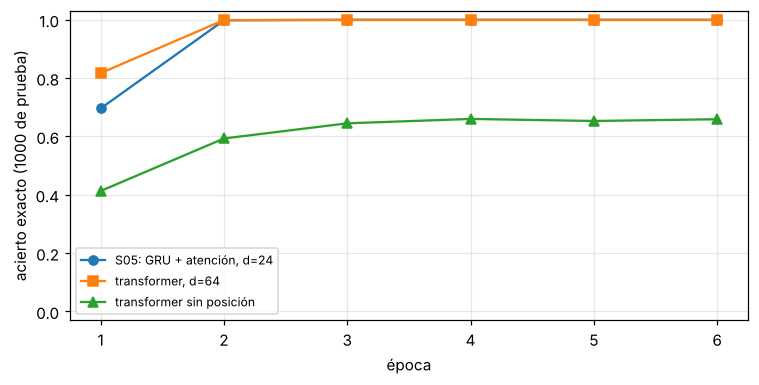

S05: GRU + atención, d=24           16,220 parámetros ·    16 s/época · exacto 1.000
transformer, d=64                  245,964 parámetros ·    38 s/época · exacto 0.999
transformer sin posición           245,964 parámetros ·    34 s/época · exacto 0.660
pre-norm, 6 capas, sin warmup      712,908 parámetros ·   107 s/época · exacto 0.999
post-norm, 6 capas, sin warmup     712,652 parámetros ·   105 s/época · exacto 0.988


In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for n, est in [('S05: GRU + atención, d=24', 'o-'), ('transformer, d=64', 's-'), ('transformer sin posición', '^-')]:
    hh = resultados[n]['historia']
    ax.plot([x['epoca'] for x in hh], [x['exacto_1000'] for x in hh], est, label=n)
ax.set_xlabel('época'); ax.set_ylabel('acierto exacto (1000 de prueba)'); ax.set_ylim(-0.03, 1.03)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
for n, r in resultados.items():
    print(f'{n:34s} {r["parametros"]:7,d} parámetros · {r["segundos_por_epoca"]:5.0f} s/época · exacto {r["exacto"]:.3f}')
json.dump(resultados, open('resultados_transformer_fechas.json', 'w'), ensure_ascii=False, indent=1)

Tres lecturas de la tabla:

1. **Recurrencia o atención:** en esta tarea corta las dos llegan al mismo acierto; la atención no gana por precisión sino por cómo escala con $T$ y con el hardware.
2. **Posición:** quitarla cuesta un tercio del acierto. La atención ve un conjunto; el orden hay que dárselo.
3. **Dónde va la LayerNorm:** a igual número de parámetros, pre-norm entrena desde el primer paso; post-norm necesita warmup.

## Tu turno · 10 minutos
1. En la sección 6, cambia `capas=2` por `capas=1`. ¿Cuántos parámetros pierdes y cuánto acierto?
2. En la sección 7, quita la posición solo en el **codificador** (deja `pos_y`). ¿Siguen los mismos errores? ¿Y si la quitas solo en el decodificador?
3. Busca en la prueba las frases que el modelo sin posición falla y que el normal acierta. ¿Tienen el año en dígitos o en palabras?
4. En la sección 8, agrega `warmup=200` al modelo post-norm. ¿Cambia la primera época?
5. Con GPU (Kaggle o Colab), repite las secciones 5 y 6 y compara los segundos por época. Luego agrega 40 palabras de relleno a cada frase (`DESPUES`): ¿qué modelo se hace más lento?

**Para pensar.** El decodificador se entrena con los 10 caracteres a la vez, pero en inferencia los produce uno por uno. ¿Qué tendría que cambiar para que la inferencia también fuera en paralelo, y qué se perdería?

In [14]:
# Tu turno

### Referencias
- Vaswani et al. (2017), *Attention Is All You Need*, NeurIPS.
- Xiong et al. (2020), *On Layer Normalization in the Transformer Architecture*, ICML.
- Radford et al. (2019), *Language Models are Unsupervised Multitask Learners* (GPT-2).
- Bahdanau, Cho y Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate*, ICLR (el modelo de 5.5).